In [1]:
# ============================================================
# STEP 1: BUSINESS UNDERSTANDING
# ============================================================

# Define the project objective
project_title = "Adult Census Income Prediction"

business_problem = (
    "Predict whether an individual earns more than "
    "$50,000 per year using census attributes."
)

# Identify the target variable
target_column = "income"

# Define the machine learning problem
problem_type = "Supervised Binary Classification"

# Define the original target categories
income_categories = ["<=50K", ">50K"]

# Define the numerical encoding for the target
target_mapping = {
    "<=50K": 0,
    ">50K": 1
}

# Define the positive class
positive_class = 1

# Display the project configuration
print("PROJECT TITLE")
print(project_title)

print("\nBUSINESS PROBLEM")
print(business_problem)

print("\nMACHINE LEARNING PROBLEM")
print(problem_type)

print("\nTARGET VARIABLE")
print(target_column)

print("\nTARGET ENCODING")
print(target_mapping)

print("\nPOSITIVE CLASS")
print("1 =", ">50K")

PROJECT TITLE
Adult Census Income Prediction

BUSINESS PROBLEM
Predict whether an individual earns more than $50,000 per year using census attributes.

MACHINE LEARNING PROBLEM
Supervised Binary Classification

TARGET VARIABLE
income

TARGET ENCODING
{'<=50K': 0, '>50K': 1}

POSITIVE CLASS
1 = >50K


In [2]:
# ============================================================
# STEP 2: DATASET UNDERSTANDING
# ============================================================

# Import the Pandas library for data analysis
import pandas as pd

# Import NumPy for numerical operations
import numpy as np

# Load the dataset
# This assumes adult.csv is in the same folder as the notebook.
df = pd.read_csv("adult.csv")

# Display a message confirming that the dataset was loaded
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# ============================================================
# INSPECT THE DATASET STRUCTURE
# ============================================================

# Display the number of rows and columns
print("Dataset Shape:")
print(df.shape)

# Display the column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display the first five records
print("\nFirst Five Records:")
display(df.head())

# Display column data types and non-null counts
print("\nDataset Information:")
df.info()

Dataset Shape:
(32561, 15)

Column Names:
['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income']

First Five Records:


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB


In [4]:
# ============================================================
# EXAMINE DESCRIPTIVE STATISTICS
# ============================================================

# Summary statistics for numerical columns
print("Numerical Descriptive Statistics:")
display(df.describe())

# Summary statistics for both numerical and categorical columns
print("\nSummary of All Columns:")
display(df.describe(include="all"))

Numerical Descriptive Statistics:


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000



Summary of All Columns:


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
count,32561.000000,32561,3.256100e+04,32561,32561.000000,32561,32561,32561,32561,32561,32561.000000,32561.000000,32561.000000,32561,32561
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,42,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22696,NaN,10501,NaN,14976,4140,13193,27816,21790,NaN,NaN,NaN,29170,24720
mean,38.581647,NaN,1.897784e+05,NaN,10.080679,NaN,NaN,NaN,NaN,NaN,1077.648844,87.303830,40.437456,NaN,NaN
std,13.640433,NaN,1.055500e+05,NaN,2.572720,NaN,NaN,NaN,NaN,NaN,7385.292085,402.960219,12.347429,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178270e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783560e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370510e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [5]:
# Check missing values recognised by pandas

In [6]:
        # Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values in the Dataset:")
print(missing_values.sum())

Missing Values in Each Column:
age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

Total Missing Values in the Dataset:
0


In [7]:
# Investigate question marks
# Select columns stored as text
text_columns = df.select_dtypes(include=["object", "str"]).columns

# Count question marks in each text column
question_mark_counts = (
    df[text_columns]
    .eq("?")
    .sum()
    .sort_values(ascending=False)
)

print("Question Mark Counts by Text Column:")
print(question_mark_counts)

print("\nTotal Question Mark Entries:")
print(question_mark_counts.sum())

Question Mark Counts by Text Column:
occupation        1843
workclass         1836
native.country     583
marital.status       0
education            0
relationship         0
race                 0
sex                  0
income               0
dtype: int64

Total Question Mark Entries:
4262


In [8]:
# Checking for duplicate records
# Count rows that are exact duplicates of earlier rows
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:")
print(duplicate_count)

# Calculate the percentage of duplicated rows
duplicate_percentage = (duplicate_count / len(df)) * 100

print("\nPercentage of Duplicate Rows:")
print(f"{duplicate_percentage:.2f}%")

Number of Duplicate Rows:
24

Percentage of Duplicate Rows:
0.07%


In [9]:
#Inspecting the target variable
# Examine the distinct income categories
print("Unique Income Labels:")
print(df["income"].unique())

print("\nIncome Category Counts:")
print(df["income"].value_counts(dropna=False))

print("\nIncome Category Percentages:")
print(
    (df["income"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Unique Income Labels:
<ArrowStringArray>
['<=50K', '>50K']
Length: 2, dtype: str

Income Category Counts:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Income Category Percentages:
income
<=50K    75.92
>50K     24.08
Name: proportion, dtype: float64


In [10]:
# Checking the number of unique values in each column
# Count the distinct values in every column
unique_counts = df.nunique(dropna=False).sort_values()

print("Unique Values in Each Column:")
print(unique_counts)

Unique Values in Each Column:
income                2
sex                   2
race                  5
relationship          6
marital.status        7
workclass             9
occupation           15
education            16
education.num        16
native.country       42
age                  73
capital.loss         92
hours.per.week       94
capital.gain        119
fnlwgt            21648
dtype: int64


###### Data Quality Assessment — Results and Decisions
Using pandas my output shows zero missing values in every column.
However, we also discovered 4,262 question-mark entries.
Decision: We will convert ? into a proper missing-value marker during data cleaning. We will then decide how to handle these missing values based on their distribution and the requirements of our machine learning pipeline.

Duplicate records
My dataset contains:

Total records: 32,561
Exact duplicate rows: 24
Duplicate percentage: 0.07%
The percentage is small, but we should not remove duplicates without considering their meaning.

Decision: We will investigate duplicates during cleaning. Because these are exact matches across all columns, removing confirmed duplicate rows is a reasonable initial approach, provided we document the decision.

Target variable distribution: Target Variable name (Income)
My target variable has two classes
| Income category | Number of records | Percentage |
| --------------- | ----------------: | ---------: |
| `<=50K`         |            24,720 |     75.92% |
| `>50K`          |             7,841 |     24.08% |
| **Total**       |        **32,561** |   **100%** |




Exploratory Data Analysis (EDA)

EDA helps us understand patterns in the data before building a model.
I will begin with the target variable, then examine categorical features and numerical features.



In [11]:
# Import libraries for data analysis and visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visual style
sns.set_theme(style="whitegrid")

print("Visualisation libraries imported successfully.")

Visualisation libraries imported successfully.


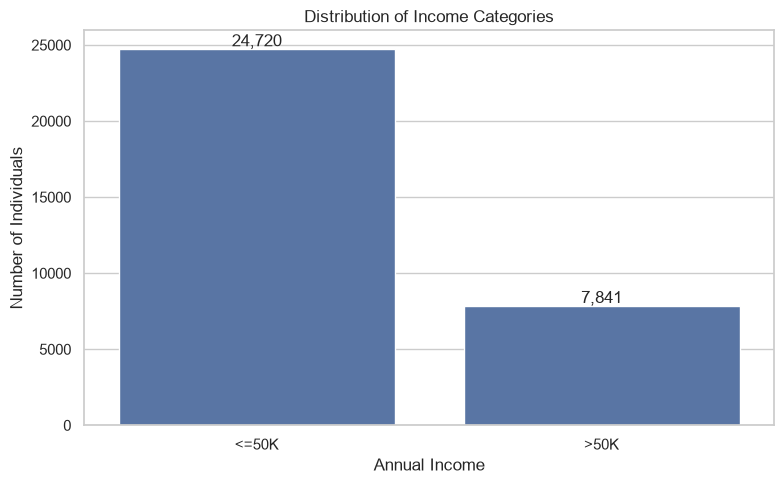

In [12]:
# Visualising the income distribution
# Count the records in each income category
income_counts = df["income"].value_counts()

# Create a bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=income_counts.index,
    y=income_counts.values
)

plt.title("Distribution of Income Categories")
plt.xlabel("Annual Income")
plt.ylabel("Number of Individuals")

# Display the values above the bars
for position, value in enumerate(income_counts.values):
    plt.text(
        position,
        value + 200,
        f"{value:,}",
        ha="center"
    )

plt.tight_layout()
plt.show()


Percentage Earning More Than $50K by education:


,Percentage earning >$50K
education,
Doctorate,74.09
Prof-school,73.44
Masters,55.66
Bachelors,41.48
Assoc-voc,26.12
Assoc-acdm,24.84
Some-college,19.02
HS-grad,15.95
12th,7.62


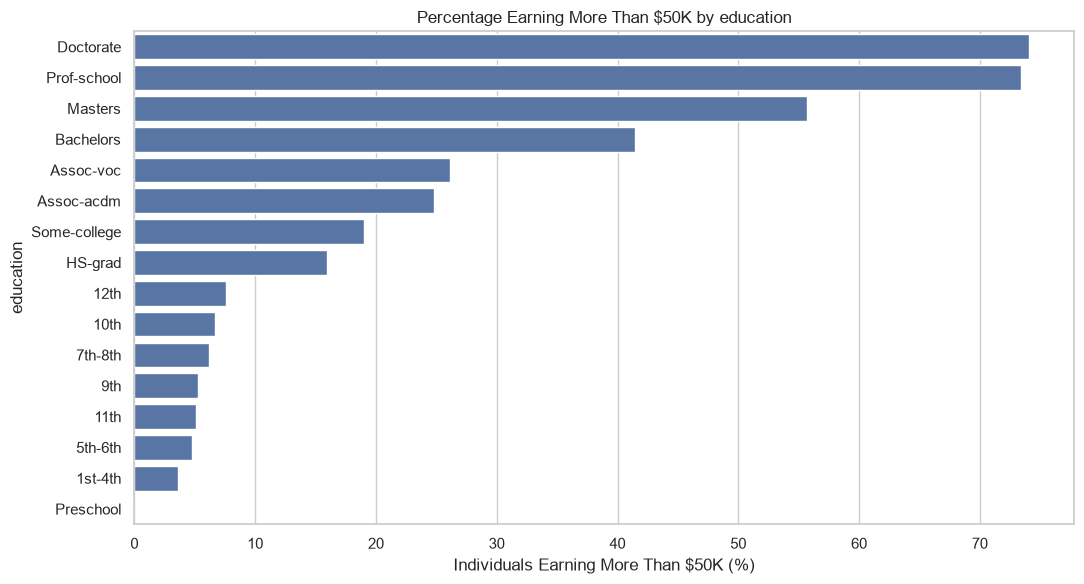


Percentage Earning More Than $50K by marital.status:


,Percentage earning >$50K
marital.status,
Married-civ-spouse,44.68
Married-AF-spouse,43.48
Divorced,10.42
Widowed,8.56
Married-spouse-absent,8.13
Separated,6.44
Never-married,4.60


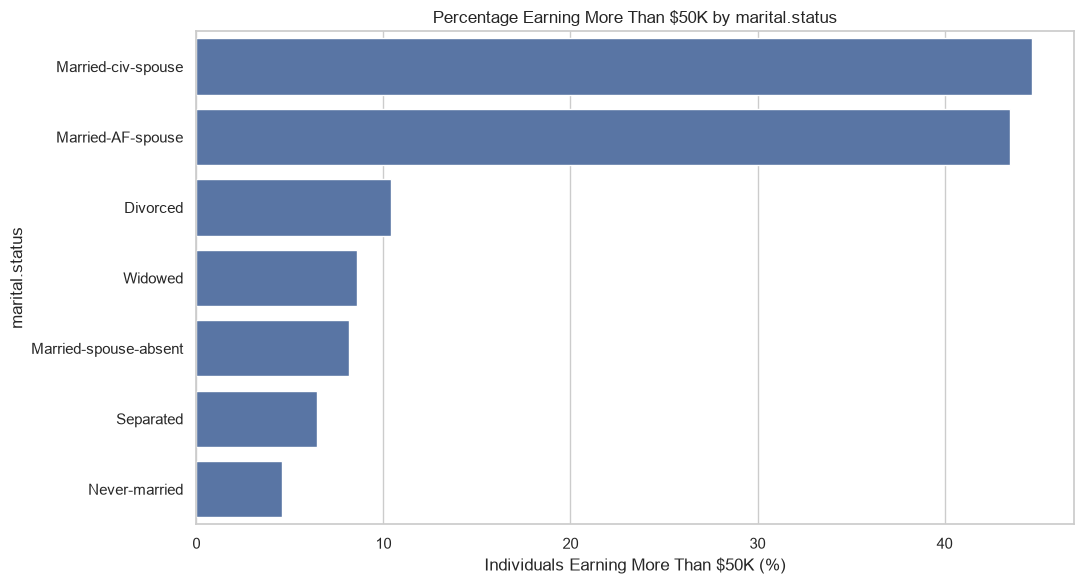


Percentage Earning More Than $50K by occupation:


,Percentage earning >$50K
occupation,
Exec-managerial,48.40
Prof-specialty,44.90
Protective-serv,32.51
Tech-support,30.50
Sales,26.93
Craft-repair,22.66
Transport-moving,20.04
Adm-clerical,13.45
Machine-op-inspct,12.49


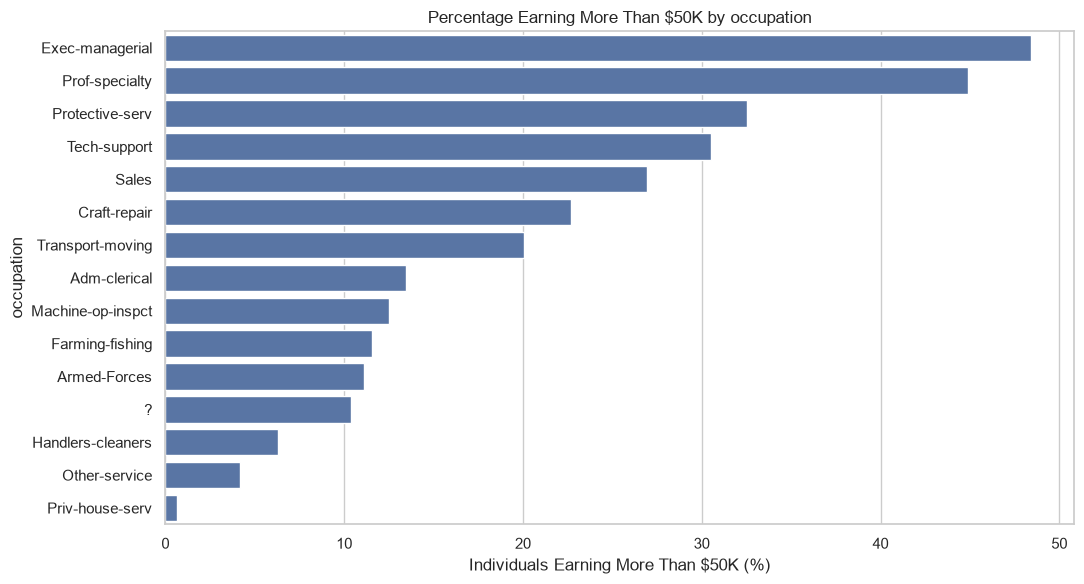

In [13]:
# Comparing income across categorical features. Beginning with three categorical features
# Create a copy for EDA so that the original dataset remains unchanged
eda_df = df.copy()

# Convert the target into a binary indicator for analysis
eda_df["income_over_50k"] = (
    eda_df["income"] == ">50K"
).astype(int)

# Categorical features to investigate
categorical_features = [
    "education",
    "marital.status",
    "occupation"
]

for feature in categorical_features:

    # Calculate the percentage earning more than $50K
    income_rate = (
        eda_df.groupby(feature, dropna=False)["income_over_50k"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    print(f"\nPercentage Earning More Than $50K by {feature}:")
    display(income_rate.round(2).to_frame(
        name="Percentage earning >$50K"
    ))

    # Visualise the percentages
    plt.figure(figsize=(11, 6))

    sns.barplot(
        x=income_rate.values,
        y=income_rate.index
    )

    plt.title(
        f"Percentage Earning More Than $50K by {feature}"
    )
    plt.xlabel("Individuals Earning More Than $50K (%)")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

In [14]:
eda_df["income"] == ">50K"

0        False
1        False
2        False
3        False
4        False
         ...  
32556    False
32557    False
32558     True
32559    False
32560    False
Name: income, Length: 32561, dtype: bool

Descriptive Statistics for Selected Numerical Features:


,age,hours.per.week,capital.gain,capital.loss
count,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,40.437456,1077.648844,87.303830
std,13.640433,12.347429,7385.292085,402.960219
min,17.000000,1.000000,0.000000,0.000000
25%,28.000000,40.000000,0.000000,0.000000
50%,37.000000,40.000000,0.000000,0.000000
75%,48.000000,45.000000,0.000000,0.000000
max,90.000000,99.000000,99999.000000,4356.000000


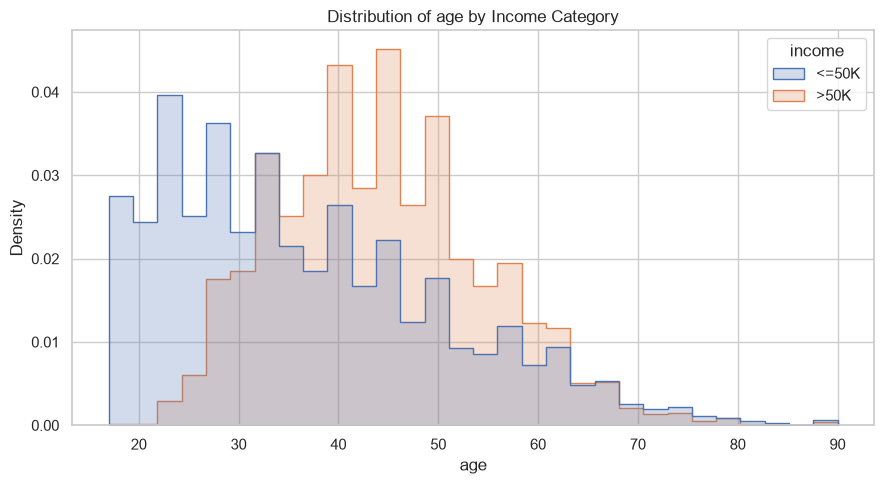

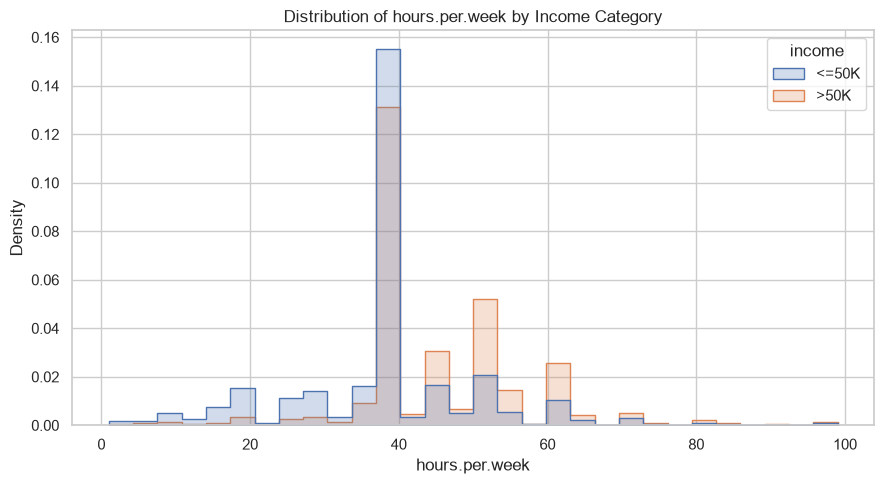

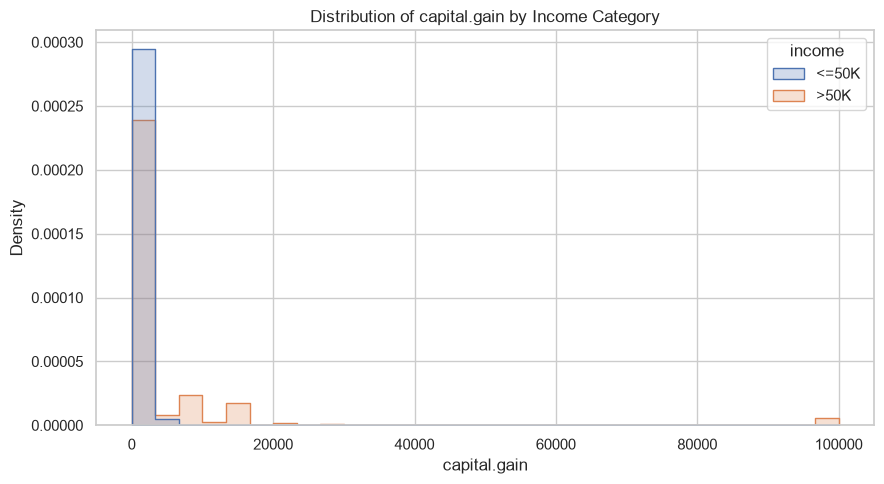

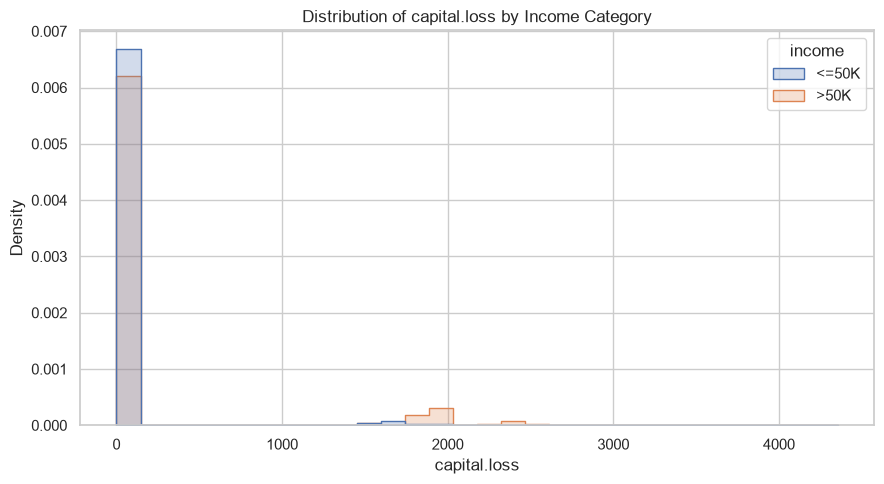

In [15]:
# Examining numerical features
# I will investigate four numerical features:
#age
#hours.per.week
#capital.gain
#capital.loss

# Numerical features selected for initial exploration
numerical_features = [
    "age",
    "hours.per.week",
    "capital.gain",
    "capital.loss"
]

# Display descriptive statistics
print("Descriptive Statistics for Selected Numerical Features:")
display(df[numerical_features].describe())

# Create histograms for the numerical features
for feature in numerical_features:

    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=df,
        x=feature,
        hue="income",
        bins=30,
        element="step",
        stat="density",
        common_norm=False
    )

    plt.title(f"Distribution of {feature} by Income Category")
    plt.xlabel(feature)
    plt.ylabel("Density")

    plt.tight_layout()
    plt.show()

###### EDA — Results and Interpretation
Finding: The dataset is imbalanced because the lower-income category is substantially more common than the higher-income category.
Business implication: A model that predicts the majority category for everyone would achieve approximately 75.92% accuracy without identifying anyone earning more than $50,000.

Decision: We will use a stratified train/test split so that the income proportions are approximately preserved in both sets. We will also evaluate precision, recall, F1-score, ROC-AUC, and the confusion matrix rather than relying on accuracy alone.
I will assess class weighting during model development rather than assuming it is automatically necessary



#### Data Cleaning and Preparation

What are we doing?
We are preparing the dataset for machine learning by addressing unknown values, checking duplicates, and validating the target variable.

Why are we doing it?
Machine learning algorithms require consistent and appropriately represented input data.

The original dataset contains question marks in the workclass, occupation, and native.country columns. These must be handled explicitly because pandas currently treats them as ordinary text.

The dataset also contains a small number of exact duplicate rows.

How are we doing it?

We will:
1. Create a separate working copy of the original dataset.
2. Convert question marks into proper missing values.
3. Remove confirmed exact duplicate rows.
4. inspect missing-value counts after cleaning.
5. Validate the target labels and dataset structure.

We will preserve the original dataset so that we can compare it with the cleaned version.

Expected result

We should have a cleaned working dataset with consistent missing-value representation and no remaining exact duplicate rows.

Decision rule

We will not delete all rows containing missing values. We will handle missing data through an appropriate preprocessing pipeline later.

We will also avoid making final feature-selection decisions until we have evaluated the data and models.

In [16]:
# Create a separate copy so that the original dataset remains unchanged
df_clean = df.copy()

# Identify text columns
text_columns = df_clean.select_dtypes(
    include=["object", "str"]
).columns

# Replace question marks with proper missing-value markers
df_clean[text_columns] = df_clean[text_columns].replace(
    "?",
    np.nan
)

print("Missing-value markers standardised successfully.")

Missing-value markers standardised successfully.


In [17]:
#Verifying missing values
print("Dataset Shape Before Cleaning:")
print(df.shape)

print("\nDataset Shape After Standardising Missing Values:")
print(df_clean.shape)

print("\nMissing Values by Column:")
print(df_clean.isnull().sum())

print("\nTotal Missing Values:")
print(df_clean.isnull().sum().sum())

Dataset Shape Before Cleaning:
(32561, 15)

Dataset Shape After Standardising Missing Values:
(32561, 15)

Missing Values by Column:
age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64

Total Missing Values:
4262


In [18]:
#Removing exact duplicate records
# Record the number of rows before removing duplicates
rows_before = len(df_clean)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Record the number of rows after removing duplicates
rows_after = len(df_clean)

print("Rows Before Duplicate Removal:", rows_before)
print("Rows After Duplicate Removal:", rows_after)
print("Duplicate Rows Removed:", rows_before - rows_after)

Rows Before Duplicate Removal: 32561
Rows After Duplicate Removal: 32537
Duplicate Rows Removed: 24


In [19]:
# Validating the cleaned dataset
print("Cleaned Dataset Shape:")
print(df_clean.shape)

print("\nRemaining Exact Duplicate Rows:")
print(df_clean.duplicated().sum())

print("\nMissing Values by Column:")
print(df_clean.isnull().sum())

print("\nIncome Categories:")
print(df_clean["income"].value_counts(dropna=False))

print("\nUnique Income Labels:")
print(df_clean["income"].unique())

print("\nData Types:")
print(df_clean.dtypes)

Cleaned Dataset Shape:
(32537, 15)

Remaining Exact Duplicate Rows:
0

Missing Values by Column:
age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     582
income               0
dtype: int64

Income Categories:
income
<=50K    24698
>50K      7839
Name: count, dtype: int64

Unique Income Labels:
<ArrowStringArray>
['<=50K', '>50K']
Length: 2, dtype: str

Data Types:
age               int64
workclass           str
fnlwgt            int64
education           str
education.num     int64
marital.status      str
occupation          str
relationship        str
race                str
sex                 str
capital.gain      int64
capital.loss      int64
hours.per.week    int64
native.country      str
income              str
dtype: 

In [20]:
import sys
from pathlib import Path

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nCurrent working directory:")
print(Path.cwd())

print("\nProject directory contents:")
for item in sorted(Path.cwd().iterdir()):
    print(item.name)

Python executable:
c:\New Eniroment for Work\Hello-Github\.venv\Scripts\python.exe

Python version:
3.14.7 (main, Sep 29 2026, 15:00:37) [MSC v.1944 64 bit (AMD64)]

Current working directory:
c:\New Eniroment for Work\Hello-Github

Project directory contents:
.git
.kilo
.python-version
.venv
.vscode
adult.csv
Census.ipynb
Churn.ipynb
mlflow.db
mlruns
pyproject.toml
README.md
src
uv.lock
WA_Fn-UseC_-Telco-Customer-Churn.csv


In [21]:
import sys
import mlflow

print("Python executable:")
print(sys.executable)

print("\nMLflow version:")
print(mlflow.__version__)

print("\nMLflow installation successful!")

Python executable:
c:\New Eniroment for Work\Hello-Github\.venv\Scripts\python.exe

MLflow version:
3.17.1

MLflow installation successful!


# MLflow Experiment Tracking

## What are we doing?

We are configuring MLflow to track experiments for the Adult Census Income Prediction project.

## Why are we doing it?

MLflow helps us record model parameters, evaluation metrics, and trained models so that experiments can be compared systematically.

## How are we doing it?

We will configure a local MLflow tracking directory and create a named experiment.

## Expected result

MLflow should identify the experiment and provide an experiment ID.

## Decision

We will use this experiment to organise subsequent model-training and evaluation runs.

In [22]:
import mlflow
from pathlib import Path

# Define a local directory for MLflow tracking
mlflow_tracking_dir = Path.cwd() / "mlruns"

# Create the directory if it does not exist
mlflow_tracking_dir.mkdir(parents=True, exist_ok=True)

# Configure MLflow to store tracking data locally
mlflow.set_tracking_uri(mlflow_tracking_dir.resolve().as_uri())

# Create or retrieve the project experiment
experiment_name = "Adult Census Income Prediction"

experiment = mlflow.set_experiment(experiment_name)

print("MLflow Tracking Configuration")
print("-" * 35)

print("Tracking URI:")
print(mlflow.get_tracking_uri())

print("\nExperiment Name:")
print(experiment.name)

print("\nExperiment ID:")
print(experiment.experiment_id)

print("\nArtifact Location:")
print(experiment.artifact_location)

MlflowException: The filesystem tracking backend (e.g., './mlruns') is in maintenance mode and will not receive further updates. Please migrate to a database backend (e.g., 'sqlite:///mlflow.db') to access the latest MLflow features. The `mlflow migrate-filestore` tool migrates your existing data losslessly. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance. If the filesystem backend is required for your workflow, set `MLFLOW_ALLOW_FILE_STORE=true` to opt out of this exception.

In [ ]:
import mlflow
from pathlib import Path

# Define the project directory
project_dir = Path.cwd()

# Define the SQLite tracking database
mlflow_database = project_dir / "mlflow.db"

# Configure MLflow to use SQLite
tracking_uri = f"sqlite:///{mlflow_database.as_posix()}"

mlflow.set_tracking_uri(tracking_uri)

# Create or retrieve the project experiment
experiment_name = "Adult Census Income Prediction"

experiment = mlflow.set_experiment(experiment_name)

print("MLflow Tracking Configuration")
print("-" * 35)

print("\nTracking URI:")
print(mlflow.get_tracking_uri())

print("\nExperiment Name:")
print(experiment.name)

print("\nExperiment ID:")
print(experiment.experiment_id)

print("\nArtifact Location:")
print(experiment.artifact_location)

2026/10/16 17:20:20 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/16 17:20:20 INFO mlflow.store.db.utils: Updating database tables
2026/10/16 17:20:22 INFO mlflow.tracking.fluent: Experiment with name 'Adult Census Income Prediction' does not exist. Creating a new experiment.


MLflow Tracking Configuration
-----------------------------------

Tracking URI:
sqlite:///c:/New Eniroment for Work/Hello-Github/mlflow.db

Experiment Name:
Adult Census Income Prediction

Experiment ID:
1

Artifact Location:
file:c:/New Eniroment for Work/Hello-Github/mlruns/1


In [ ]:
import mlflow

# Select the project experiment
mlflow.set_experiment("Adult Census Income Prediction")

# Create a test run
with mlflow.start_run(run_name="mlflow_tracking_test"):

    # Log an illustrative parameter
    mlflow.log_param("test_parameter", "tracking_verification")

    # Log illustrative metrics to test metric tracking
    mlflow.log_metric("test_accuracy", 0.80)
    mlflow.log_metric("test_f1_score", 0.75)

    # Capture the run ID
    test_run_id = mlflow.active_run().info.run_id

print("MLflow test run completed.")
print("Test Run ID:", test_run_id)

MLflow test run completed.
Test Run ID: 48be0fd046fc4a92a005e428aa211be4


In [ ]:
import mlflow
from mlflow.tracking import MlflowClient

# Connect to the configured MLflow tracking store
client = MlflowClient()

# Retrieve the test run
run = client.get_run(test_run_id)

print("Recorded Run Information")
print("-" * 35)

print("\nRun ID:")
print(run.info.run_id)

print("\nRun Name:")
print(run.data.tags.get("mlflow.runName"))

print("\nRecorded Parameters:")
print(run.data.params)

print("\nRecorded Metrics:")
print(run.data.metrics)

print("\nRun Status:")
print(run.info.status)

Recorded Run Information
-----------------------------------

Run ID:
48be0fd046fc4a92a005e428aa211be4

Run Name:
mlflow_tracking_test

Recorded Parameters:
{'test_parameter': 'tracking_verification'}

Recorded Metrics:
{'test_accuracy': 0.8, 'test_f1_score': 0.75}

Run Status:
FINISHED


In [ ]:
# Define the Features and Target
# Define the target column
target_column = "income"

# Create the feature matrix
X = df_clean.drop(columns=[target_column]).copy()

# Convert the target into binary numerical values
y = df_clean[target_column].map({
    "<=50K": 0,
    ">50K": 1
})

# Verify the mapping
print("Target Mapping:")
print({"<=50K": 0, ">50K": 1})

print("\nFeature Matrix Shape:")
print(X.shape)

print("\nTarget Shape:")
print(y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Values:")
print(y.unique())

print("\nTarget Class Counts:")
print(y.value_counts().sort_index())

print("\nTarget Class Percentages:")
print(
    (y.value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Target Mapping:
{'<=50K': 0, '>50K': 1}

Feature Matrix Shape:
(32537, 14)

Target Shape:
(32537,)

Feature Columns:
['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country']

Target Values:
[0 1]

Target Class Counts:
income
0    24698
1     7839
Name: count, dtype: int64

Target Class Percentages:
income
0    75.91
1    24.09
Name: proportion, dtype: float64


In [ ]:
#Validating the feature and target definitions
# Check that X and y have matching row counts
assert len(X) == len(y), "X and y have different numbers of rows."

# Check that the target contains no missing values
assert y.notna().all(), "The target contains missing values."

# Check that the target contains only the expected binary values
assert set(y.unique()) == {0, 1}, "Unexpected target values found."

# Check that the target column is not present in X
assert target_column not in X.columns, "Target leakage detected in X."

print("Feature and target validation passed.")

Feature and target validation passed.


In [ ]:
# Outlier Detection and Investigation
# Numerical features selected for outlier investigation
outlier_features = [
    "age",
    "hours.per.week",
    "capital.gain",
    "capital.loss",
    "fnlwgt",
    "education.num"
]

# Calculate the IQR statistics for each feature
outlier_results = []

for feature in outlier_features:

    # Calculate the first and third quartiles
    Q1 = df_clean[feature].quantile(0.25)
    Q3 = df_clean[feature].quantile(0.75)

    # Calculate the interquartile range
    IQR = Q3 - Q1

    # Calculate the statistical boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify observations outside the boundaries
    outlier_mask = (
        (df_clean[feature] < lower_bound) |
        (df_clean[feature] > upper_bound)
    )

    # Count the potential outliers
    outlier_count = outlier_mask.sum()

    # Calculate their percentage of the dataset
    outlier_percentage = (
        outlier_count / len(df_clean)
    ) * 100

    # Store the results
    outlier_results.append({
        "Feature": feature,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outlier_count,
        "Outlier Percentage": outlier_percentage
    })

# Display the results
outlier_summary = pd.DataFrame(outlier_results)

display(
    outlier_summary.round(2)
)


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
0,age,28.0,48.0,20.0,-2.0,78.0,142,0.44
1,hours.per.week,40.0,45.0,5.0,32.5,52.5,9002,27.67
2,capital.gain,0.0,0.0,0.0,0.0,0.0,2712,8.34
3,capital.loss,0.0,0.0,0.0,0.0,0.0,1519,4.67
4,fnlwgt,117827.0,236993.0,119166.0,-60922.0,415742.0,993,3.05
5,education.num,9.0,12.0,3.0,4.5,16.5,1193,3.67


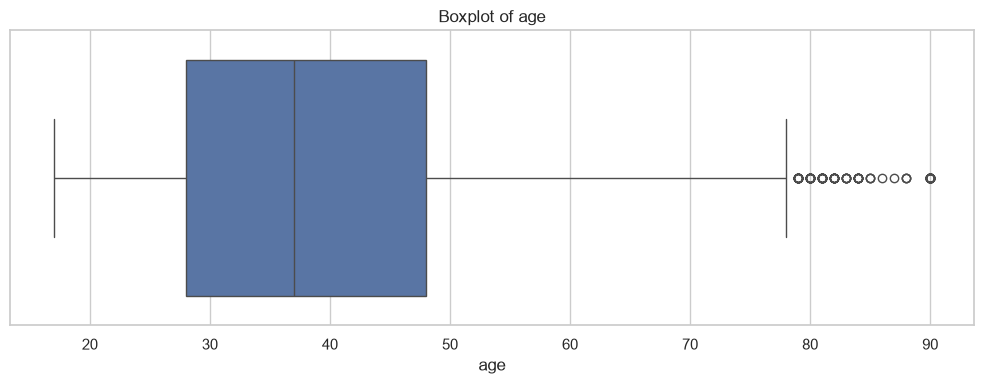

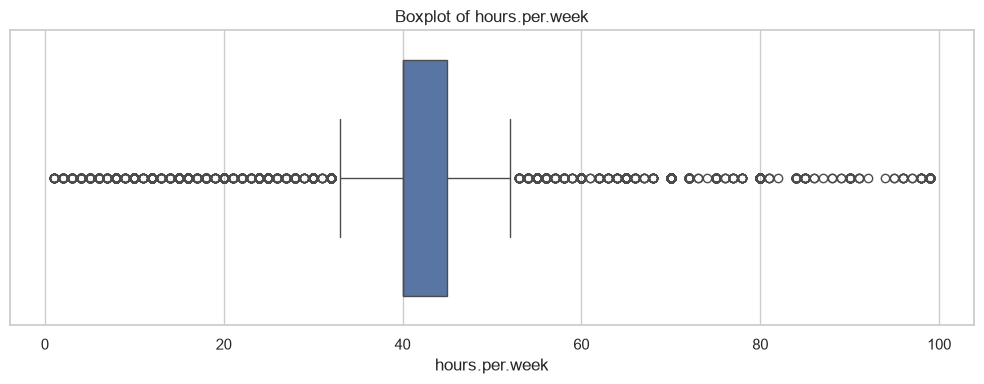

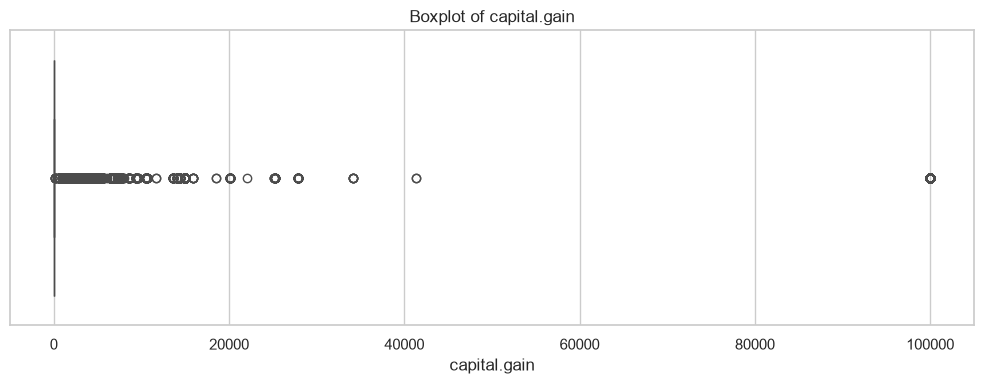

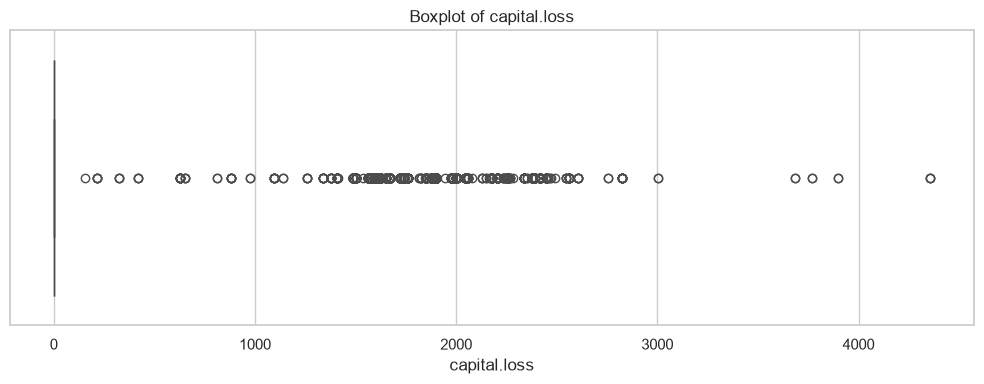

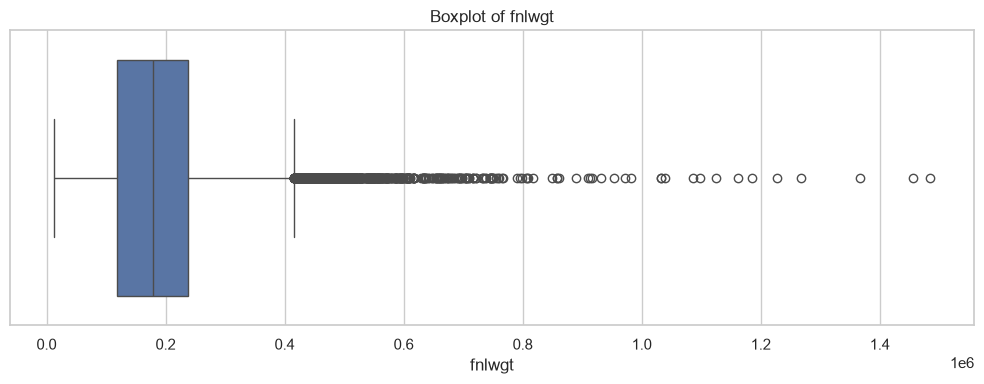

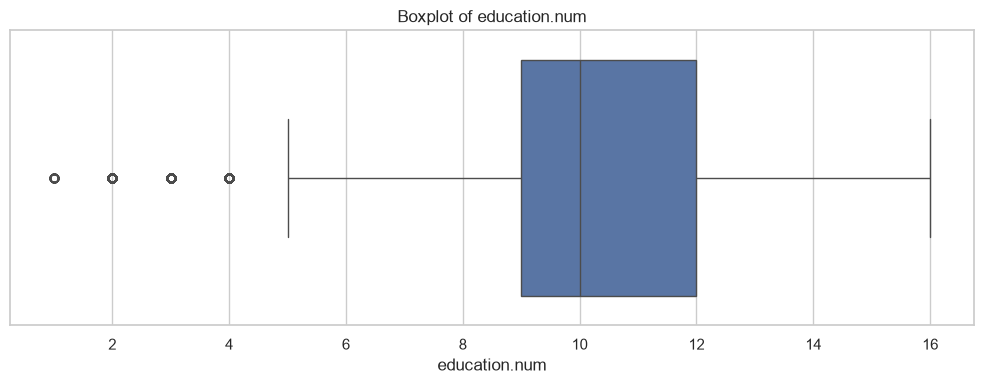

In [ ]:
#Visualise Outliers
# Create boxplots for the selected numerical features
for feature in outlier_features:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=df_clean[feature]
    )

    plt.title(f"Boxplot of {feature}")
    plt.xlabel(feature)

    plt.tight_layout()
    plt.show()

In [ ]:
# Checking observed range
# Inspect the ranges and distinct values of selected features
for feature in outlier_features:

    print(f"\nFeature: {feature}")
    print("-" * 35)

    print("Minimum:", df_clean[feature].min())
    print("Maximum:", df_clean[feature].max())
    print("Unique Values:", df_clean[feature].nunique())

    print("\nFive Smallest Values:")
    print(df_clean[feature].nsmallest(5).tolist())

    print("\nFive Largest Values:")
    print(df_clean[feature].nlargest(5).tolist())


Feature: age
-----------------------------------
Minimum: 17
Maximum: 90
Unique Values: 73

Five Smallest Values:
[17, 17, 17, 17, 17]

Five Largest Values:
[90, 90, 90, 90, 90]

Feature: hours.per.week
-----------------------------------
Minimum: 1
Maximum: 99
Unique Values: 94

Five Smallest Values:
[1, 1, 1, 1, 1]

Five Largest Values:
[99, 99, 99, 99, 99]

Feature: capital.gain
-----------------------------------
Minimum: 0
Maximum: 99999
Unique Values: 119

Five Smallest Values:
[0, 0, 0, 0, 0]

Five Largest Values:
[99999, 99999, 99999, 99999, 99999]

Feature: capital.loss
-----------------------------------
Minimum: 0
Maximum: 4356
Unique Values: 92

Five Smallest Values:
[0, 0, 0, 0, 0]

Five Largest Values:
[4356, 4356, 4356, 3900, 3900]

Feature: fnlwgt
-----------------------------------
Minimum: 12285
Maximum: 1484705
Unique Values: 21648

Five Smallest Values:
[12285, 13769, 14878, 18827, 19214]

Five Largest Values:
[1484705, 1455435, 1366120, 1268339, 1226583]

Feature:

In [23]:
# Recalculate the IQR summary with clearly named columns

outlier_features = [
    "age",
    "hours.per.week",
    "capital.gain",
    "capital.loss",
    "fnlwgt",
    "education.num"
]

outlier_results = []

for feature in outlier_features:

    Q1 = df_clean[feature].quantile(0.25)
    Q3 = df_clean[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df_clean[feature] < lower_bound) |
        (df_clean[feature] > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())

    outlier_percentage = (
        outlier_count / len(df_clean)
    ) * 100

    outlier_results.append({
        "Feature": feature,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outlier_count,
        "Outlier Percentage": outlier_percentage
    })

outlier_summary = pd.DataFrame(outlier_results)

display(
    outlier_summary.round(2)
)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
0,age,28.0,48.0,20.0,-2.0,78.0,142,0.44
1,hours.per.week,40.0,45.0,5.0,32.5,52.5,9002,27.67
2,capital.gain,0.0,0.0,0.0,0.0,0.0,2712,8.34
3,capital.loss,0.0,0.0,0.0,0.0,0.0,1519,4.67
4,fnlwgt,117827.0,236993.0,119166.0,-60922.0,415742.0,993,3.05
5,education.num,9.0,12.0,3.0,4.5,16.5,1193,3.67


In [24]:
# Display the IQR summary with a clean index
outlier_summary = outlier_summary.reset_index(drop=True)

display(
    outlier_summary.style.format({
        "Q1": "{:,.2f}",
        "Q3": "{:,.2f}",
        "IQR": "{:,.2f}",
        "Lower Bound": "{:,.2f}",
        "Upper Bound": "{:,.2f}",
        "Potential Outliers": "{:,.0f}",
        "Outlier Percentage": "{:.2f}%"
    })
)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
0,age,28.00,48.00,20.00,-2.00,78.00,142,0.44%
1,hours.per.week,40.00,45.00,5.00,32.50,52.50,"9,002",27.67%
2,capital.gain,0.00,0.00,0.00,0.00,0.00,"2,712",8.34%
3,capital.loss,0.00,0.00,0.00,0.00,0.00,"1,519",4.67%
4,fnlwgt,"117,827.00","236,993.00","119,166.00","-60,922.00","415,742.00",993,3.05%
5,education.num,9.00,12.00,3.00,4.50,16.50,"1,193",3.67%


Our outlier decision

Based on the evidence gathered so far, we will retain all observations and not apply automatic outlier removal.

The reasons are:

age values up to 90 are not inherently invalid.
hours.per.week contains unusual values, but the boxplot does not prove they are data errors.
capital.gain and capital.loss are highly concentrated at zero, making the standard IQR rule less informative.
fnlwgt represents a census sampling weight.
education.num represents discrete education levels.

#Stratified 80/20 Train/Test Split
We are dividing the dataset into two sets:

80% training data: Used to train and tune our models.
20% test data: Reserved for evaluating the final model on unseen records.
Why are we doing it?

We need to evaluate whether our model generalises to observations it did not use during training.

###### Because our target is imbalanced, we will use stratification to preserve approximately the same income-class proportions in both sets.


# Step 9: Stratified Train/Test Split

## What are we doing?

We are dividing the features and target into training and test sets using an 80/20 split.

## Why are we doing it?

The training set will be used to fit and select our models. The test set will be reserved for final evaluation.

## How are we doing it?

We will use train_test_split from scikit-learn with stratification based on the target variable.

We will also set a random state so that the split can be reproduced.

## Expected result

Approximately 80% of the observations will be assigned to training and 20% to testing. Both sets should preserve approximately the same proportions of the two income classes.

## Decision rule

The test set will not be used to fit preprocessing transformations, select features, tune model parameters, or choose the final model.

In [25]:
from sklearn.model_selection import train_test_split

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTraining Income Distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting Income Distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

NameError: name 'X' is not defined

In [26]:
# Recreate the feature matrix from the cleaned dataset
X = df_clean.drop(columns=["income"]).copy()

# Recreate the binary target variable
y = df_clean["income"].map({
    "<=50K": 0,
    ">50K": 1
})

# Verify that the variables exist
print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Class Counts:")
print(y.value_counts().sort_index())

# Validate the variables
assert len(X) == len(y), "X and y have different numbers of rows."
assert y.notna().all(), "The target contains missing values."
assert set(y.unique()) == {0, 1}, "Unexpected target values found."

print("\nFeature and target variables recreated successfully.")

Feature Matrix Shape: (32537, 14)
Target Shape: (32537,)

Target Class Counts:
income
0    24698
1     7839
Name: count, dtype: int64

Feature and target variables recreated successfully.


In [27]:
#Train and Split test again
from sklearn.model_selection import train_test_split

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTraining Income Distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting Income Distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training Feature Shape: (26029, 14)
Testing Feature Shape: (6508, 14)

Training Target Shape: (26029,)
Testing Target Shape: (6508,)

Training Income Distribution (%):
income
0    75.91
1    24.09
Name: proportion, dtype: float64

Testing Income Distribution (%):
income
0    75.91
1    24.09
Name: proportion, dtype: float64


# Step 10: Preprocessing Pipeline

## What are we doing?

We are building a preprocessing pipeline for numerical and categorical features.

## Why are we doing it?

The dataset contains text categories, missing values, and numerical features with different scales.

Machine learning algorithms require suitable numerical inputs, and preprocessing must be performed without using information from the test set.

## How are we doing it?

We will:
1. Identify numerical and categorical columns from the training features.
2. Impute missing numerical values using the median.
3. Impute missing categorical values using the most frequent category.
4. One-hot encode categorical features.
5. Scale numerical features using StandardScaler.
6. Combine the transformations using ColumnTransformer.

## Expected result

We should obtain a preprocessing pipeline that can transform the training and test datasets consistently.

## Decision rule

The preprocessing pipeline will be fitted using the training data only. The test data will be transformed using the already-fitted pipeline.

Any feature selection, SMOTE, or model-specific handling will be introduced later within the training and validation workflow.

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("Preprocessing libraries imported successfully.")

Preprocessing libraries imported successfully.


In [29]:
# Identify numerical features from the training data
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical features from the training data
categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Number of Numerical Features:", len(numerical_features))
print("Numerical Features:")
print(numerical_features)

print("\nNumber of Categorical Features:", len(categorical_features))
print("Categorical Features:")
print(categorical_features)

Number of Numerical Features: 6
Numerical Features:
['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']

Number of Categorical Features: 8
Categorical Features:
['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']


In [30]:
#Creating the numerical and categorical pipelines
# Numerical preprocessing pipeline
numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Categorical preprocessing pipeline
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

print("Numerical preprocessing pipeline created.")
print("Categorical preprocessing pipeline created.")

Numerical preprocessing pipeline created.
Categorical preprocessing pipeline created.


In [31]:
# Combine the preprocessing pipelines
# Combine the numerical and categorical transformations
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Combined preprocessing pipeline created successfully.")

Combined preprocessing pipeline created successfully.


In [32]:
#Fit the pipeline on training data only
# Fit preprocessing on the training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform the test data using the fitted preprocessing pipeline
X_test_processed = preprocessor.transform(X_test)

print("Training Data Before Preprocessing:", X_train.shape)
print("Training Data After Preprocessing:", X_train_processed.shape)

print("\nTest Data Before Preprocessing:", X_test.shape)
print("Test Data After Preprocessing:", X_test_processed.shape)

print("\nMissing Values in Training Data Before Imputation:")
print(X_train.isnull().sum().sum())

print("\nMissing Values in Test Data Before Imputation:")
print(X_test.isnull().sum().sum())

Training Data Before Preprocessing: (26029, 14)
Training Data After Preprocessing: (26029, 104)

Test Data Before Preprocessing: (6508, 14)
Test Data After Preprocessing: (6508, 104)

Missing Values in Training Data Before Imputation:
3419

Missing Values in Test Data Before Imputation:
842


important methodological decision we need to make first: how to combine feature selection, cross-validation, class weighting, SMOTE, and MLflow without introducing data leakage.

###### Preparing the Model-Training Workflow
Before training our models, we need to agree on the approach to class imbalance.

My target distribution is approximately:

Class 0 (<=50K): 75.91%
Class 1 (>50K): 24.09%

We will compare appropriate strategies rather than assuming one is best.


In [33]:
import numpy as np

print("Processed Training Data Contains Missing Values:")
print(np.isnan(X_train_processed).sum())

print("\nProcessed Test Data Contains Missing Values:")
print(np.isnan(X_test_processed).sum())

print("\nProcessed Training Data Contains Infinite Values:")
print(np.isinf(X_train_processed).sum())

print("\nProcessed Test Data Contains Infinite Values:")
print(np.isinf(X_test_processed).sum())

Processed Training Data Contains Missing Values:


TypeError: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

In [34]:
import numpy as np
from scipy import sparse

print("Training data type:")
print(type(X_train_processed))

print("\nTest data type:")
print(type(X_test_processed))

print("\nTraining data is sparse:")
print(sparse.issparse(X_train_processed))

print("\nTest data is sparse:")
print(sparse.issparse(X_test_processed))

print("\nTraining data shape:")
print(X_train_processed.shape)

print("\nTest data shape:")
print(X_test_processed.shape)

Training data type:
<class 'scipy.sparse._csr.csr_matrix'>

Test data type:
<class 'scipy.sparse._csr.csr_matrix'>

Training data is sparse:
True

Test data is sparse:
True

Training data shape:
(26029, 104)

Test data shape:
(6508, 104)


In [35]:
# Validate missing and infinite values
import numpy as np
from scipy import sparse

def check_processed_data(data, dataset_name):

    print(f"\n{dataset_name}")
    print("-" * 40)

    if sparse.issparse(data):

        # Inspect the stored values in a sparse matrix
        stored_values = data.data

    else:

        # Convert a dense array to a NumPy array
        stored_values = np.asarray(data)

    missing_count = np.isnan(stored_values).sum()
    infinite_count = np.isinf(stored_values).sum()

    print("Missing values:", missing_count)
    print("Infinite values:", infinite_count)

    return missing_count, infinite_count


train_missing, train_infinite = check_processed_data(
    X_train_processed,
    "Processed Training Data"
)

test_missing, test_infinite = check_processed_data(
    X_test_processed,
    "Processed Test Data"
)

print("\nValidation Summary")
print("-" * 40)

if (
    train_missing == 0
    and train_infinite == 0
    and test_missing == 0
    and test_infinite == 0
):
    print("PASS: No missing or infinite values detected.")
else:
    print("CHECK REQUIRED: Missing or infinite values were detected.")


Processed Training Data
----------------------------------------
Missing values: 0
Infinite values: 0

Processed Test Data
----------------------------------------
Missing values: 0
Infinite values: 0

Validation Summary
----------------------------------------
PASS: No missing or infinite values detected.


## 15. Establishing a Baseline Model

Before training more advanced machine learning models, we establish a baseline using DummyClassifier.

The baseline predicts the most frequent income class for every observation. It provides a reference point against which we can compare our trained models.

We will evaluate the baseline using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.

The baseline is not expected to identify meaningful patterns in the data. Its purpose is to help us determine whether our machine learning models provide an improvement over a simple prediction strategy.

In [36]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Create the baseline model
baseline_model = DummyClassifier(strategy="most_frequent")

# Train the model using the training data
baseline_model.fit(X_train_processed, y_train)

# Generate predictions for the training data
y_train_baseline_pred = baseline_model.predict(X_train_processed)

# Generate predictions for the test data
y_test_baseline_pred = baseline_model.predict(X_test_processed)

# Calculate baseline metrics on the test data
baseline_accuracy = accuracy_score(y_test, y_test_baseline_pred)

baseline_precision = precision_score(
    y_test,
    y_test_baseline_pred,
    zero_division=0
)

baseline_recall = recall_score(
    y_test,
    y_test_baseline_pred,
    zero_division=0
)

baseline_f1 = f1_score(
    y_test,
    y_test_baseline_pred,
    zero_division=0
)

baseline_roc_auc = roc_auc_score(
    y_test,
    baseline_model.predict_proba(X_test_processed)[:, 1]
)

baseline_cm = confusion_matrix(y_test, y_test_baseline_pred)

# Display the results
print("BASELINE MODEL RESULTS")
print("=" * 40)

print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-score:  {baseline_f1:.4f}")
print(f"ROC-AUC:   {baseline_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(baseline_cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_baseline_pred,
        target_names=["Income <= $50K", "Income > $50K"],
        zero_division=0
    )
)

BASELINE MODEL RESULTS
Accuracy:  0.7591
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
ROC-AUC:   0.5000

Confusion Matrix:
[[4940    0]
 [1568    0]]

Classification Report:
                precision    recall  f1-score   support

Income <= $50K       0.76      1.00      0.86      4940
 Income > $50K       0.00      0.00      0.00      1568

      accuracy                           0.76      6508
     macro avg       0.38      0.50      0.43      6508
  weighted avg       0.58      0.76      0.66      6508



### Baseline Model Findings

The baseline model achieved an accuracy of 75.91%, which reflects the proportion of observations belonging to the majority income class.

However, the model achieved zero precision, zero recall, and an F1-score of zero for individuals earning more than $50K. Its ROC-AUC was 0.50, indicating no ability to distinguish between the two income classes.

The confusion matrix showed that all 1,568 test observations belonging to the higher-income class were incorrectly classified.

These results demonstrate that accuracy alone is insufficient for evaluating this imbalanced classification problem.

We will use the baseline as a reference point and aim to improve the identification of individuals earning more than $50K through machine learning, appropriate feature selection, cross-validation, and class imbalance handling.

In [37]:
# Deep Learning MOdels
import sys
import importlib.util

print("Python executable:")
print(sys.executable)

print("\nTensorFlow installed:")
print(importlib.util.find_spec("tensorflow") is not None)

print("\nMLflow installed:")
print(importlib.util.find_spec("mlflow") is not None)

Python executable:
c:\New Eniroment for Work\Hello-Github\.venv\Scripts\python.exe

TensorFlow installed:
True

MLflow installed:
True


## 17. Preparing Data for Deep Learning

TensorFlow neural networks require numerical input data.

Our preprocessing pipeline produced sparse matrices because one-hot encoding creates many zero values. We will convert these matrices into dense NumPy arrays for the initial neural network.

We will preserve the existing 80/20 train-test split and use the training data to fit the model. The test data will remain untouched until final evaluation.

In [38]:
import numpy as np

# Convert sparse matrices into dense NumPy arrays
X_train_dl = X_train_processed.toarray().astype(np.float32)
X_test_dl = X_test_processed.toarray().astype(np.float32)

# Convert target labels into NumPy arrays
y_train_dl = np.asarray(y_train, dtype=np.float32)
y_test_dl = np.asarray(y_test, dtype=np.float32)

print("DEEP LEARNING DATA PREPARATION")
print("=" * 45)

print("Training features shape:", X_train_dl.shape)
print("Test features shape:", X_test_dl.shape)

print("Training target shape:", y_train_dl.shape)
print("Test target shape:", y_test_dl.shape)

print("\nTraining features data type:", X_train_dl.dtype)
print("Test features data type:", X_test_dl.dtype)

print("\nUnique training target values:", np.unique(y_train_dl))
print("Unique test target values:", np.unique(y_test_dl))

DEEP LEARNING DATA PREPARATION
Training features shape: (26029, 104)
Test features shape: (6508, 104)
Training target shape: (26029,)
Test target shape: (6508,)

Training features data type: float32
Test features data type: float32

Unique training target values: [0. 1.]
Unique test target values: [0. 1.]


In [39]:
# Validate the prepared data before training

assert X_train_dl.shape[0] == len(y_train_dl), \
    "Training features and labels have different row counts."

assert X_test_dl.shape[0] == len(y_test_dl), \
    "Test features and labels have different row counts."

assert X_train_dl.shape[1] == X_test_dl.shape[1], \
    "Training and test feature counts do not match."

assert set(np.unique(y_train_dl)).issubset({0.0, 1.0}), \
    "Unexpected values found in training labels."

assert set(np.unique(y_test_dl)).issubset({0.0, 1.0}), \
    "Unexpected values found in test labels."

assert np.isfinite(X_train_dl).all(), \
    "Training features contain missing or infinite values."

assert np.isfinite(X_test_dl).all(), \
    "Test features contain missing or infinite values."

print("PASS: All deep learning data validation checks succeeded.")
print("PASS: Training and test feature dimensions match.")
print("PASS: Target labels contain only 0 and 1.")
print("PASS: No missing or infinite feature values were detected.")

PASS: All deep learning data validation checks succeeded.
PASS: Training and test feature dimensions match.
PASS: Target labels contain only 0 and 1.
PASS: No missing or infinite feature values were detected.


## Creating the Training and Validation Sets

The original dataset was split into training and test sets using an 80/20 split.

To compare our deep learning architectures fairly, we will divide the training data again. We will use 80% of the existing training data for model fitting and 20% for validation.

The validation set will help us compare the neural networks and monitor overfitting.

The test set will remain untouched until we have selected the best model.

In [40]:
from sklearn.model_selection import train_test_split

# Split the existing training data into training and validation sets
X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
    X_train_dl,
    y_train_dl,
    test_size=0.20,
    random_state=42,
    stratify=y_train_dl
)

print("NEURAL NETWORK TRAINING AND VALIDATION SPLIT")
print("=" * 50)

print("Training features:", X_train_nn.shape)
print("Training labels:", y_train_nn.shape)

print("Validation features:", X_val_nn.shape)
print("Validation labels:", y_val_nn.shape)

print("\nTraining positive-class percentage:",
      round(y_train_nn.mean() * 100, 2), "%")

print("Validation positive-class percentage:",
      round(y_val_nn.mean() * 100, 2), "%")

print("\nTest features:", X_test_dl.shape)
print("Test labels:", y_test_dl.shape)

NEURAL NETWORK TRAINING AND VALIDATION SPLIT
Training features: (20823, 104)
Training labels: (20823,)
Validation features: (5206, 104)
Validation labels: (5206,)

Training positive-class percentage: 24.09 %
Validation positive-class percentage: 24.09 %

Test features: (6508, 104)
Test labels: (6508,)


In [41]:
import tensorflow as tf
import mlflow
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)
print("MLflow version:", mlflow.__version__)

print("\nAvailable TensorFlow devices:")
print(tf.config.list_physical_devices())

TensorFlow version: 2.22.0-rc0
MLflow version: 3.17.1

Available TensorFlow devices:
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [42]:
# Identify the classes present in the training labels
classes = np.unique(y_train_nn)

# Calculate class weights from the training subset only
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_nn
)

# Convert the results into the dictionary expected by Keras
class_weights = {
    int(class_label): float(weight)
    for class_label, weight in zip(classes, weights)
}

print("CLASS WEIGHTS")
print("=" * 35)

for class_label, weight in class_weights.items():
    print(f"Class {class_label}: {weight:.4f}")

print("\nClass 0 = Income <= $50K")
print("Class 1 = Income > $50K")

CLASS WEIGHTS
Class 0: 0.6587
Class 1: 2.0752

Class 0 = Income <= $50K
Class 1 = Income > $50K


In [43]:
# Configure MLflow to use the existing SQLite tracking database
project_dir = Path.cwd()

mlflow_database = project_dir / "mlflow.db"

tracking_uri = f"sqlite:///{mlflow_database.as_posix()}"

mlflow.set_tracking_uri(tracking_uri)

experiment_name = "Adult Census Income Prediction"

experiment = mlflow.set_experiment(experiment_name)

print("MLflow experiment configured successfully.")
print("Experiment name:", experiment_name)
print("Experiment ID:", experiment.experiment_id)
print("Tracking URI:", mlflow.get_tracking_uri())

MLflow experiment configured successfully.
Experiment name: Adult Census Income Prediction
Experiment ID: 1
Tracking URI: sqlite:///c:/New Eniroment for Work/Hello-Github/mlflow.db


## 21. Building and Training Three Deep Learning Models

We will train three feedforward neural networks with different architectures.

The first model will have one hidden layer. The second will have two hidden layers. The third will have three hidden layers and dropout regularisation.

All models will use the same training and validation datasets, loss function, optimiser, and class weights to support a fair comparison.

Early stopping will monitor validation loss and restore the best model weights observed during training.

We will record the model parameters, training history, and validation metrics in MLflow.

In [44]:
# Defining the three deep learning architecture
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

# Make the experiments more reproducible
tf.keras.utils.set_random_seed(42)

input_features = X_train_nn.shape[1]


def build_simple_nn():
    """Neural network with one hidden layer."""
    model = keras.Sequential([
        keras.Input(shape=(input_features,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ], name="simple_neural_network")

    return model


def build_deep_nn():
    """Neural network with two hidden layers."""
    model = keras.Sequential([
        keras.Input(shape=(input_features,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ], name="deep_neural_network")

    return model


def build_regularised_nn():
    """Neural network with three hidden layers and dropout."""
    model = keras.Sequential([
        keras.Input(shape=(input_features,)),
        layers.Dense(128, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.30),
        layers.Dense(1, activation="sigmoid")
    ], name="regularised_deep_neural_network")

    return model


model_builders = {
    "Simple_NN": build_simple_nn,
    "Deep_NN": build_deep_nn,
    "Regularised_Deep_NN": build_regularised_nn
}

print("Three neural network architectures defined successfully.")
print("Number of input features:", input_features)

for model_name, builder in model_builders.items():
    model = builder()
    print(f"{model_name}: {model.count_params():,} trainable parameters")

Three neural network architectures defined successfully.
Number of input features: 104
Simple_NN: 3,393 trainable parameters
Deep_NN: 8,833 trainable parameters
Regularised_Deep_NN: 23,809 trainable parameters


## 22. Training and Tracking the Neural Networks

We will train the three neural network architectures using a common training procedure.

Each model will use Adam optimisation, binary cross-entropy loss, and class weights to account for the imbalance in the target variable.

Early stopping will monitor validation loss and restore the weights from the best epoch.

We will evaluate each model on the validation dataset and log its parameters, metrics, training history, and trained model to MLflow.

The validation results will be used to select a model for final evaluation on the untouched test dataset.

In [47]:
import mlflow.tensorflow

print("MLflow TensorFlow integration loaded successfully.")

print(
    "TensorFlow model logging available:",
    hasattr(mlflow.tensorflow, "log_model")
)

MLflow TensorFlow integration loaded successfully.
TensorFlow model logging available: True


In [48]:
import json
import mlflow
import numpy as np
import pandas as pd
import tensorflow as tf

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
from tensorflow import keras

# Use the existing MLflow experiment
mlflow.set_experiment("Adult Census Income Prediction")

# Training configuration shared by all three models
EPOCHS = 30
BATCH_SIZE = 256
LEARNING_RATE = 0.001
PATIENCE = 5

# Store the results and trained models in memory
experiment_results = []
trained_models = {}
training_histories = {}


def train_and_track_model(model_name, model_builder):

    print("\n" + "=" * 65)
    print(f"TRAINING MODEL: {model_name}")
    print("=" * 65)

    # Reset random seeds for more reproducible initialisation
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    # Build and compile the model
    model = model_builder()

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="roc_auc")
        ]
    )

    # Stop training when validation loss stops improving
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
        mode="min",
        verbose=1
    )

    # Start a separate MLflow run for this model
    with mlflow.start_run(run_name=model_name):

        # Record model configuration
        mlflow.log_params({
            "model_name": model_name,
            "architecture": model.name,
            "input_features": input_features,
            "epochs_max": EPOCHS,
            "batch_size": BATCH_SIZE,
            "learning_rate": LEARNING_RATE,
            "optimizer": "Adam",
            "loss_function": "binary_crossentropy",
            "class_weight_0": class_weights[0],
            "class_weight_1": class_weights[1],
            "early_stopping_patience": PATIENCE,
            "validation_split_fraction_of_original_data": 0.16
        })

        # Record the number of trainable parameters
        mlflow.log_param(
            "trainable_parameters",
            model.count_params()
        )

        # Train the neural network
        history = model.fit(
            X_train_nn,
            y_train_nn,
            validation_data=(X_val_nn, y_val_nn),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            class_weight=class_weights,
            callbacks=[early_stopping],
            verbose=1
        )

        # Early stopping restores the best validation-loss weights
        best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

        # Predict probabilities on the validation dataset
        y_val_prob = model.predict(
            X_val_nn,
            verbose=0
        ).ravel()

        # Convert probabilities to class predictions
        y_val_pred = (y_val_prob >= 0.5).astype(int)

        # Calculate validation metrics
        val_accuracy = accuracy_score(
            y_val_nn, y_val_pred
        )

        val_precision = precision_score(
            y_val_nn,
            y_val_pred,
            zero_division=0
        )

        val_recall = recall_score(
            y_val_nn,
            y_val_pred,
            zero_division=0
        )

        val_f1 = f1_score(
            y_val_nn,
            y_val_pred,
            zero_division=0
        )

        val_roc_auc = roc_auc_score(
            y_val_nn,
            y_val_prob
        )

        val_loss = float(
            history.history["val_loss"][best_epoch - 1]
        )

        val_cm = confusion_matrix(
            y_val_nn,
            y_val_pred
        )

        # Record final validation metrics in MLflow
        mlflow.log_metrics({
            "validation_accuracy": float(val_accuracy),
            "validation_precision": float(val_precision),
            "validation_recall": float(val_recall),
            "validation_f1": float(val_f1),
            "validation_roc_auc": float(val_roc_auc),
            "validation_loss": val_loss,
            "best_epoch": best_epoch
        })

        # Log training history as a CSV artifact
        history_df = pd.DataFrame(history.history)

        history_path = (
            Path.cwd() / f"{model_name}_training_history.csv"
        )

        history_df.to_csv(history_path, index=False)

        mlflow.log_artifact(
            str(history_path),
            artifact_path="training_history"
        )

        # Save the trained Keras model to MLflow
        mlflow.tensorflow.log_model(
            model,
            name="trained_model"
        )

        # Store the trained model and its history in memory
        trained_models[model_name] = model
        training_histories[model_name] = history.history

        # Save the model results
        result = {
            "model_name": model_name,
            "trainable_parameters": model.count_params(),
            "best_epoch": best_epoch,
            "validation_accuracy": val_accuracy,
            "validation_precision": val_precision,
            "validation_recall": val_recall,
            "validation_f1": val_f1,
            "validation_roc_auc": val_roc_auc,
            "validation_loss": val_loss,
            "confusion_matrix": val_cm.tolist()
        }

        experiment_results.append(result)

        print(f"\n{model_name} RESULTS")
        print("-" * 45)
        print(f"Best epoch:       {best_epoch}")
        print(f"Accuracy:         {val_accuracy:.4f}")
        print(f"Precision:        {val_precision:.4f}")
        print(f"Recall:           {val_recall:.4f}")
        print(f"F1-score:         {val_f1:.4f}")
        print(f"ROC-AUC:          {val_roc_auc:.4f}")
        print(f"Validation loss:  {val_loss:.4f}")

        print("\nValidation confusion matrix:")
        print(val_cm)

        print("\nMLflow run ID:")
        print(mlflow.active_run().info.run_id)

    return result

In [49]:
# Train and track all three neural network models

for model_name, model_builder in model_builders.items():
    train_and_track_model(model_name, model_builder)

print("\n" + "=" * 65)
print("ALL THREE NEURAL NETWORK EXPERIMENTS COMPLETED")
print("=" * 65)


TRAINING MODEL: Simple_NN

Epoch 1/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6603 - loss: 0.5592 - precision: 0.4019 - recall: 0.8391 - roc_auc: 0.8166 - val_accuracy: 0.7841 - val_loss: 0.4746 - val_precision: 0.5335 - val_recall: 0.8246 - val_roc_auc: 0.8822
Epoch 2/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7998 - loss: 0.4171 - precision: 0.5570 - recall: 0.8264 - roc_auc: 0.8925 - val_accuracy: 0.8010 - val_loss: 0.4179 - val_precision: 0.5573 - val_recall: 0.8453 - val_roc_auc: 0.8985
Epoch 3/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8050 - loss: 0.3901 - precision: 0.5643 - recall: 0.8372 - roc_auc: 0.9032 - val_accuracy: 0.8073 - val_loss: 0.4048 - val_precision: 0.5660 - val_recall: 0.8581 - val_roc_auc: 0.9042
Epoch 4/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8088 - loss: 0.3802 - precision: 0.5694 - recall: 0.8473 - roc_auc: 0.9076 - val_accuracy: 0.8104 - val_loss: 0.3983 - val_precision: 0.5702 - val_recall: 0.8652 -

2026/10/19 13:00:46 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\New Eniroment for Work\Hello-Github
2026/10/19 13:00:46 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/10/19 13:00:46 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\New Eniroment for Work\Hello-Github
2026/10/19 13:00:46 INFO mlflow.utils.environment: Detected uv project at c:\New Eniroment for Work\Hello-Github. Attempting to export requirements via 'uv export'.
2026/10/19 13:00:54 INFO mlflow.utils.uv_utils: Exported 112 dependencies via uv
2026/10/19 13:00:54 INFO mlflow.utils.environment: Successfully exported 112 requirements from uv project. Skipping package capture based inference.
2026/10/19 13:00:55 WARNING mlflow.utils.environment


Simple_NN RESULTS
---------------------------------------------
Best epoch:       30
Accuracy:         0.8175
Precision:        0.5822
Recall:           0.8589
F1-score:         0.6939
ROC-AUC:          0.9133
Validation loss:  0.3758

Validation confusion matrix:
[[3179  773]
 [ 177 1077]]

MLflow run ID:
1118525608464016bd28714c460c24b7

TRAINING MODEL: Deep_NN
Epoch 1/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.7663 - loss: 0.4838 - precision: 0.5095 - recall: 0.8104 - roc_auc: 0.8578 - val_accuracy: 0.7933 - val_loss: 0.4127 - val_precision: 0.5447 - val_recall: 0.8644 - val_roc_auc: 0.9018
Epoch 2/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8070 - loss: 0.3776 - precision: 0.5659 - recall: 0.8553 - roc_auc: 0.9086 - val_accuracy: 0.8118 - val_loss: 0.3888 - val_precision: 0.5720 - val_recall: 0.8684 - val_roc_auc: 0.9103
Epoch 3/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8136 - loss: 0.3663 - precision: 0.5758 - recall: 0.8601 - roc_auc: 0.91

2026/10/19 13:01:02 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\New Eniroment for Work\Hello-Github
2026/10/19 13:01:02 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/10/19 13:01:02 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\New Eniroment for Work\Hello-Github
2026/10/19 13:01:02 INFO mlflow.utils.environment: Detected uv project at c:\New Eniroment for Work\Hello-Github. Attempting to export requirements via 'uv export'.
2026/10/19 13:01:02 INFO mlflow.utils.uv_utils: Exported 112 dependencies via uv
2026/10/19 13:01:02 INFO mlflow.utils.environment: Successfully exported 112 requirements from uv project. Skipping package capture based inference.
2026/10/19 13:01:03 WARNING mlflow.utils.environment


Deep_NN RESULTS
---------------------------------------------
Best epoch:       13
Accuracy:         0.8196
Precision:        0.5865
Recall:           0.8517
F1-score:         0.6946
ROC-AUC:          0.9130
Validation loss:  0.3700

Validation confusion matrix:
[[3199  753]
 [ 186 1068]]

MLflow run ID:
e8c351c959dd4ad9a41d9231f95f2fe5

TRAINING MODEL: Regularised_Deep_NN
Epoch 1/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.7631 - loss: 0.4724 - precision: 0.5052 - recall: 0.8186 - roc_auc: 0.8581 - val_accuracy: 0.7881 - val_loss: 0.4226 - val_precision: 0.5357 - val_recall: 0.9035 - val_roc_auc: 0.9069
Epoch 2/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8084 - loss: 0.3786 - precision: 0.5672 - recall: 0.8639 - roc_auc: 0.9080 - val_accuracy: 0.8016 - val_loss: 0.3953 - val_precision: 0.5551 - val_recall: 0.8876 - val_roc_auc: 0.9125
Epoch 3/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8143 - loss: 0.3681 - precision: 0.5763 - recall: 0.8661 - roc

2026/10/19 13:01:13 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\New Eniroment for Work\Hello-Github
2026/10/19 13:01:13 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/10/19 13:01:13 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\New Eniroment for Work\Hello-Github
2026/10/19 13:01:13 INFO mlflow.utils.environment: Detected uv project at c:\New Eniroment for Work\Hello-Github. Attempting to export requirements via 'uv export'.
2026/10/19 13:01:13 INFO mlflow.utils.uv_utils: Exported 112 dependencies via uv
2026/10/19 13:01:13 INFO mlflow.utils.environment: Successfully exported 112 requirements from uv project. Skipping package capture based inference.
2026/10/19 13:01:13 WARNING mlflow.utils.environment


Regularised_Deep_NN RESULTS
---------------------------------------------
Best epoch:       7
Accuracy:         0.8139
Precision:        0.5760
Recall:           0.8612
F1-score:         0.6903
ROC-AUC:          0.9127
Validation loss:  0.3729

Validation confusion matrix:
[[3157  795]
 [ 174 1080]]

MLflow run ID:
d353a59dbc364982a8263b4cc00b8895

ALL THREE NEURAL NETWORK EXPERIMENTS COMPLETED


In [50]:
# Compare the validation results from the three models

results_df = pd.DataFrame(experiment_results)

comparison_columns = [
    "model_name",
    "trainable_parameters",
    "best_epoch",
    "validation_accuracy",
    "validation_precision",
    "validation_recall",
    "validation_f1",
    "validation_roc_auc",
    "validation_loss"
]

results_df = results_df[comparison_columns].sort_values(
    by="validation_f1",
    ascending=False
).reset_index(drop=True)

print("DEEP LEARNING MODEL COMPARISON")
print("=" * 65)

display(results_df.round(4))

DEEP LEARNING MODEL COMPARISON


,model_name,trainable_parameters,best_epoch,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_loss
0,Deep_NN,8833,13,0.8196,0.5865,0.8517,0.6946,0.9130,0.3700
1,Simple_NN,3393,30,0.8175,0.5822,0.8589,0.6939,0.9133,0.3758
2,Regularised_Deep_NN,23809,7,0.8139,0.5760,0.8612,0.6903,0.9127,0.3729


In [ ]:
# Selecting the best candidate using evidence


## 25. Verifying MLflow Experiment Tracking

We trained three neural network architectures and logged their training configurations, validation metrics, training histories, and model artifacts in MLflow.

We will now retrieve the experiment runs to verify that the results were recorded successfully.

This provides an auditable record of our model comparisons and supports reproducibility.

In [51]:
import mlflow
import pandas as pd

# Retrieve the existing experiment
experiment = mlflow.get_experiment_by_name(
    "Adult Census Income Prediction"
)

if experiment is None:
    raise ValueError(
        "The Adult Census Income Prediction experiment was not found."
    )

# Retrieve all runs from the experiment
mlflow_runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    output_format="pandas"
)

# Display the most relevant columns
columns_to_display = [
    "run_id",
    "status",
    "tags.mlflow.runName",
    "metrics.validation_accuracy",
    "metrics.validation_precision",
    "metrics.validation_recall",
    "metrics.validation_f1",
    "metrics.validation_roc_auc",
    "metrics.validation_loss"
]

# Keep only columns available in the retrieved results
available_columns = [
    column for column in columns_to_display
    if column in mlflow_runs.columns
]

mlflow_summary = mlflow_runs[available_columns].copy()

print("MLFLOW EXPERIMENT VERIFICATION")
print("=" * 60)

print("Experiment name:", experiment.name)
print("Experiment ID:", experiment.experiment_id)
print("Total recorded runs:", len(mlflow_summary))

display(mlflow_summary)

MLFLOW EXPERIMENT VERIFICATION
Experiment name: Adult Census Income Prediction
Experiment ID: 1
Total recorded runs: 4


,run_id,status,tags.mlflow.runName,metrics.validation_accuracy,metrics.validation_precision,metrics.validation_recall,metrics.validation_f1,metrics.validation_roc_auc,metrics.validation_loss
0,d353a59dbc364982a8263b4cc00b8895,FINISHED,Regularised_Deep_NN,0.813869,0.576000,0.861244,0.690316,0.912729,0.372858
1,e8c351c959dd4ad9a41d9231f95f2fe5,FINISHED,Deep_NN,0.819631,0.586491,0.851675,0.694634,0.913004,0.369969
2,1118525608464016bd28714c460c24b7,FINISHED,Simple_NN,0.817518,0.582162,0.858852,0.693943,0.913280,0.375801
3,48be0fd046fc4a92a005e428aa211be4,FINISHED,mlflow_tracking_test,NaN,NaN,NaN,NaN,NaN,NaN


In [52]:
# Display the name, status, and validation metrics for each MLflow run

display_columns = [
    "tags.mlflow.runName",
    "status",
    "metrics.validation_accuracy",
    "metrics.validation_precision",
    "metrics.validation_recall",
    "metrics.validation_f1",
    "metrics.validation_roc_auc",
    "metrics.validation_loss"
]

available_columns = [
    col for col in display_columns
    if col in mlflow_runs.columns
]

display(
    mlflow_runs[available_columns].sort_values(
        by="tags.mlflow.runName"
    ).reset_index(drop=True)
)

,tags.mlflow.runName,status,metrics.validation_accuracy,metrics.validation_precision,metrics.validation_recall,metrics.validation_f1,metrics.validation_roc_auc,metrics.validation_loss
0,Deep_NN,FINISHED,0.819631,0.586491,0.851675,0.694634,0.913004,0.369969
1,Regularised_Deep_NN,FINISHED,0.813869,0.576000,0.861244,0.690316,0.912729,0.372858
2,Simple_NN,FINISHED,0.817518,0.582162,0.858852,0.693943,0.913280,0.375801
3,mlflow_tracking_test,FINISHED,NaN,NaN,NaN,NaN,NaN,NaN


## 26. Final Evaluation of the Selected Deep Learning Model

Based on the validation results, Deep_NN was selected as the leading candidate because it achieved the highest validation F1-score.

We will now evaluate this model on the held-out test dataset, which has not been used for training or model selection.

We will calculate accuracy, precision, recall, F1-score, ROC-AUC, the confusion matrix, and the classification report.

These results will provide an estimate of how well the model generalises to unseen observations.

In [53]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Select the best candidate based on validation F1-score
best_model_name = "Deep_NN"
best_model = trained_models[best_model_name]

# Predict probabilities for the positive class
y_test_prob = best_model.predict(
    X_test_dl,
    verbose=0
).ravel()

# Convert probabilities to binary predictions
y_test_pred = (y_test_prob >= 0.5).astype(int)

# Calculate test metrics
test_accuracy = accuracy_score(y_test_dl, y_test_pred)

test_precision = precision_score(
    y_test_dl, y_test_pred, zero_division=0
)

test_recall = recall_score(
    y_test_dl, y_test_pred, zero_division=0
)

test_f1 = f1_score(
    y_test_dl, y_test_pred, zero_division=0
)

test_roc_auc = roc_auc_score(
    y_test_dl, y_test_prob
)

test_cm = confusion_matrix(y_test_dl, y_test_pred)

print("FINAL TEST RESULTS")
print("=" * 50)
print("Selected model:", best_model_name)
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(test_cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test_dl.astype(int),
        y_test_pred,
        labels=[0, 1],
        target_names=["Income <= $50K", "Income > $50K"],
        zero_division=0
    )
)

FINAL TEST RESULTS
Selected model: Deep_NN
Accuracy:  0.8205
Precision: 0.5914
Recall:    0.8253
F1-score:  0.6890
ROC-AUC:   0.9043

Confusion Matrix:
[[4046  894]
 [ 274 1294]]

Classification Report:
                precision    recall  f1-score   support

Income <= $50K       0.94      0.82      0.87      4940
 Income > $50K       0.59      0.83      0.69      1568

      accuracy                           0.82      6508
     macro avg       0.76      0.82      0.78      6508
  weighted avg       0.85      0.82      0.83      6508



## 28. Comparing Validation and Test Performance

We selected Deep_NN because it achieved the highest validation F1-score among the three neural network architectures.

We will now compare its validation and test metrics to assess whether its performance remains reasonably consistent on unseen observations.

The validation metrics were used during model selection. The test metrics provide our final evaluation of the selected candidate.

In [54]:
# Compare validation and test performance

validation_f1 = float(
    results_df.loc[
        results_df["model_name"] == "Deep_NN",
        "validation_f1"
    ].iloc[0]
)

validation_accuracy = float(
    results_df.loc[
        results_df["model_name"] == "Deep_NN",
        "validation_accuracy"
    ].iloc[0]
)

validation_recall = float(
    results_df.loc[
        results_df["model_name"] == "Deep_NN",
        "validation_recall"
    ].iloc[0]
)

validation_roc_auc = float(
    results_df.loc[
        results_df["model_name"] == "Deep_NN",
        "validation_roc_auc"
    ].iloc[0]
)

performance_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Validation": [
        validation_accuracy,
        validation_recall,
        validation_f1,
        validation_roc_auc
    ],
    "Test": [
        test_accuracy,
        test_recall,
        test_f1,
        test_roc_auc
    ]
})

performance_comparison["Difference"] = (
    performance_comparison["Test"]
    - performance_comparison["Validation"]
)

print("DEEP_NN: VALIDATION VS TEST")
print("=" * 45)

display(performance_comparison.round(4))

DEEP_NN: VALIDATION VS TEST


,Metric,Validation,Test,Difference
0,Accuracy,0.8196,0.8205,0.0009
1,Recall,0.8517,0.8253,-0.0264
2,F1-score,0.6946,0.6890,-0.0056
3,ROC-AUC,0.9130,0.9043,-0.0087


## Logging the Final Evaluation in MLflow

Deep_NN was selected using validation F1-score.

We will record its final test metrics in a separate MLflow run. This preserves the distinction between the validation results used for model selection and the test results used for final evaluation.

The final evaluation run will include the selected model name, evaluation metrics, classification threshold, and confusion matrix.

In [55]:
import json
import mlflow

mlflow.set_experiment("Adult Census Income Prediction")

with mlflow.start_run(run_name="Deep_NN_Final_Test_Evaluation"):

    # Record the evaluation configuration
    mlflow.log_params({
        "selected_model": "Deep_NN",
        "evaluation_dataset": "Held-out test set",
        "classification_threshold": 0.5,
        "selection_metric": "Validation F1-score",
        "validation_f1": validation_f1,
        "test_observations": len(y_test_dl)
    })

    # Record the final test metrics
    mlflow.log_metrics({
        "test_accuracy": float(test_accuracy),
        "test_precision": float(test_precision),
        "test_recall": float(test_recall),
        "test_f1": float(test_f1),
        "test_roc_auc": float(test_roc_auc)
    })

    # Record the confusion matrix as a JSON artifact
    confusion_matrix_path = (
        Path.cwd() / "Deep_NN_test_confusion_matrix.json"
    )

    with open(confusion_matrix_path, "w", encoding="utf-8") as file:
        json.dump(
            {
                "labels": ["Income <= $50K", "Income > $50K"],
                "matrix": test_cm.tolist()
            },
            file,
            indent=4
        )

    mlflow.log_artifact(
        str(confusion_matrix_path),
        artifact_path="final_evaluation"
    )

    final_evaluation_run_id = (
        mlflow.active_run().info.run_id
    )

print("Final evaluation logged successfully.")
print("Selected model: Deep_NN")
print("Test F1-score:", round(test_f1, 4))
print("Test ROC-AUC:", round(test_roc_auc, 4))
print("MLflow run ID:", final_evaluation_run_id)

Final evaluation logged successfully.
Selected model: Deep_NN
Test F1-score: 0.689
Test ROC-AUC: 0.9043
MLflow run ID: 0a277d0a2a7547cb895f90fc307e47d4


## 31. Final Model Selection and Justification

Three neural network architectures were trained and evaluated:

1. Simple_NN
2. Deep_NN
3. Regularised_Deep_NN

The models were compared using validation accuracy, precision, recall, F1-score, ROC-AUC, and validation loss.

Deep_NN was selected as the leading candidate because it achieved the highest validation F1-score of 0.6946 and the lowest validation loss of 0.3700.

The Simple_NN model achieved a very similar validation F1-score of 0.6939, while the Regularised_Deep_NN model achieved 0.6903.

The difference between Deep_NN and Simple_NN was small, so we do not claim that Deep_NN is conclusively superior. It is the preferred candidate under our predefined F1-score selection rule.

The selected model was subsequently evaluated on the untouched test dataset.

Final test results:

- Accuracy: 82.05%
- Precision: 59.14%
- Recall: 82.53%
- F1-score: 68.90%
- ROC-AUC: 90.43%

The test F1-score was close to the validation F1-score, providing encouraging evidence of generalisation to the held-out observations.

The baseline model achieved 75.91% accuracy but failed to identify any observations in the higher-income class. Deep_NN provides a more useful classification approach because it identifies a substantial proportion of the positive class.

The model is suitable as an experimental result for this project. Further validation, fairness assessment, and monitoring would be required before any consequential real-world use.

In [56]:
# Verifying final ML flow experiment record
import mlflow
import pandas as pd

experiment = mlflow.get_experiment_by_name(
    "Adult Census Income Prediction"
)

all_runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    output_format="pandas"
)

print("FINAL MLFLOW EXPERIMENT AUDIT")
print("=" * 60)

print("Experiment:", experiment.name)
print("Experiment ID:", experiment.experiment_id)
print("Total recorded runs:", len(all_runs))

run_columns = [
    "tags.mlflow.runName",
    "status",
    "metrics.validation_f1",
    "metrics.validation_roc_auc",
    "metrics.test_accuracy",
    "metrics.test_f1",
    "metrics.test_roc_auc"
]

available_columns = [
    column for column in run_columns
    if column in all_runs.columns
]

display(all_runs[available_columns])

FINAL MLFLOW EXPERIMENT AUDIT
Experiment: Adult Census Income Prediction
Experiment ID: 1
Total recorded runs: 5


,tags.mlflow.runName,status,metrics.validation_f1,metrics.validation_roc_auc,metrics.test_accuracy,metrics.test_f1,metrics.test_roc_auc
0,Deep_NN_Final_Test_Evaluation,FINISHED,NaN,NaN,0.820529,0.689031,0.904265
1,Regularised_Deep_NN,FINISHED,0.690316,0.912729,NaN,NaN,NaN
2,Deep_NN,FINISHED,0.694634,0.913004,NaN,NaN,NaN
3,Simple_NN,FINISHED,0.693943,0.913280,NaN,NaN,NaN
4,mlflow_tracking_test,FINISHED,NaN,NaN,0.800000,NaN,NaN


## 37. Training History and Learning Curves

We will visualise the training and validation loss for each neural network.

Training loss measures the model's error on the training data. Validation loss measures its error on the validation data.

Comparing the two helps us understand how the model learns and whether its performance on unseen validation observations begins to deteriorate.

The plots will help us investigate potential overfitting and compare the learning behaviour of the three architectures.

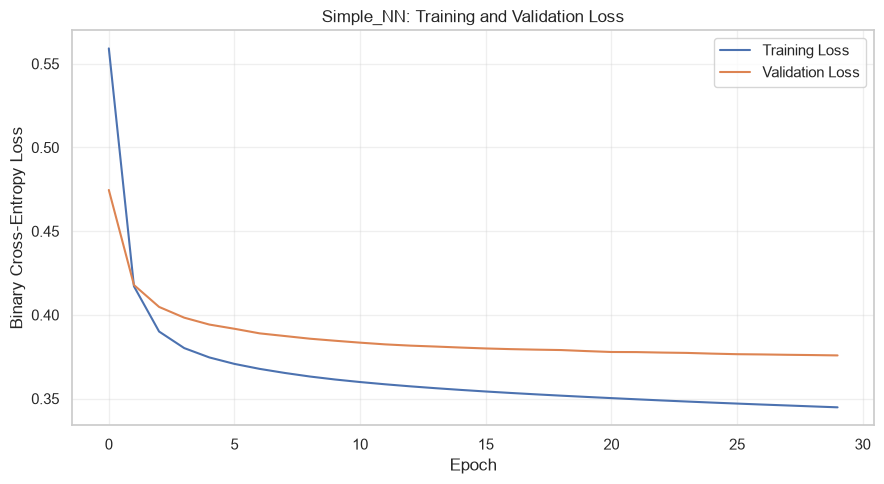

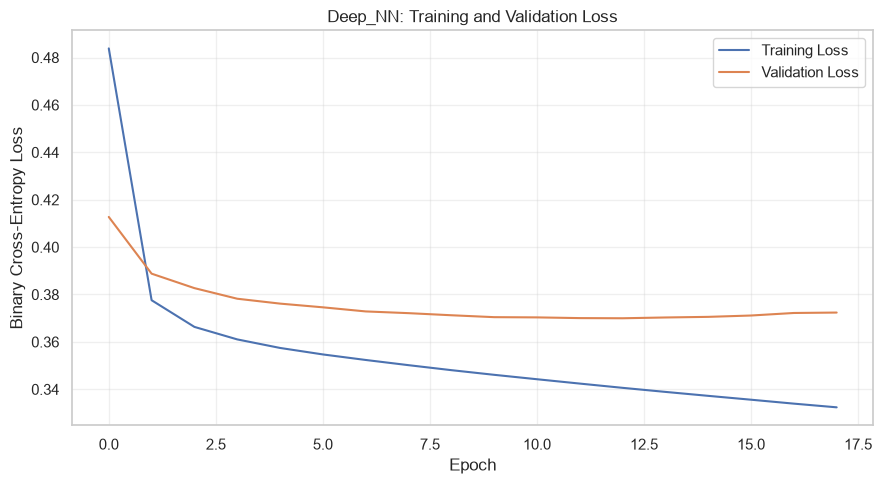

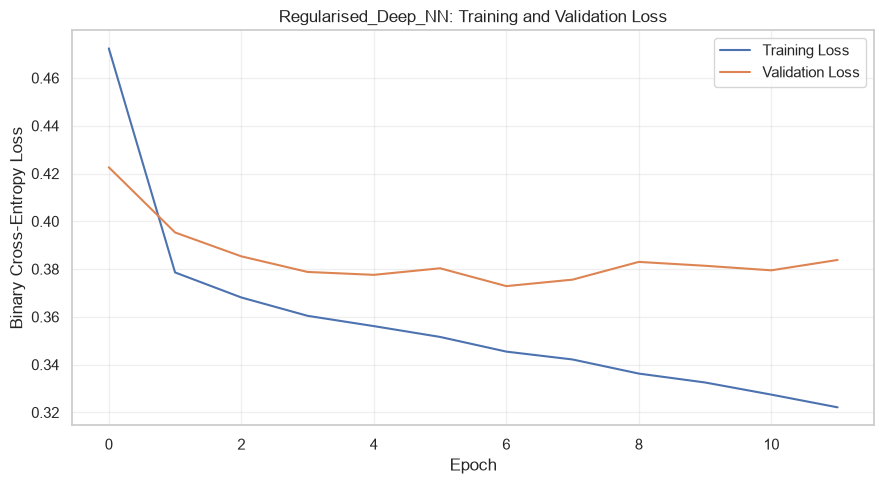

In [57]:
#Plot training and validation loss
import matplotlib.pyplot as plt

# Plot the training and validation loss for each model
for model_name, history in training_histories.items():

    plt.figure(figsize=(9, 5))

    plt.plot(
        history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history["val_loss"],
        label="Validation Loss"
    )

    plt.title(f"{model_name}: Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Binary Cross-Entropy Loss")

    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

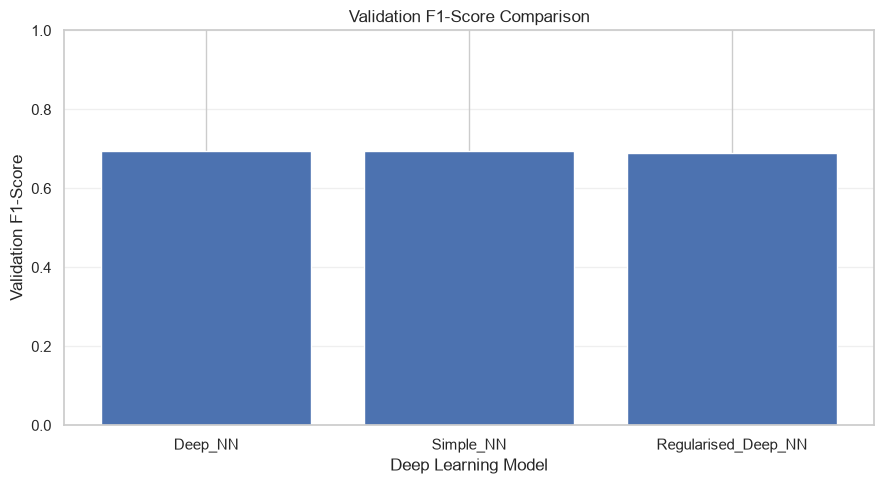

In [58]:
#Compare the validation F1-scores visually
import matplotlib.pyplot as plt

# Sort models by validation F1-score
plot_df = results_df.sort_values(
    by="validation_f1",
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    plot_df["model_name"],
    plot_df["validation_f1"]
)

plt.title("Validation F1-Score Comparison")
plt.xlabel("Deep Learning Model")
plt.ylabel("Validation F1-Score")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 41. Training Curve Analysis and Model Comparison

The training and validation curves were examined for all three neural network architectures.

### Simple_NN

Training and validation loss decreased throughout training. The validation loss gradually levelled off, suggesting that the model learned useful patterns without strong visual evidence of severe overfitting.

### Deep_NN

Training loss decreased throughout training, while validation loss improved initially and then began to rise slightly. The best validation loss occurred at epoch 13.

This behaviour is consistent with mild overfitting after the best validation-loss epoch. Early stopping helped preserve the weights associated with the lowest validation loss.

### Regularised_Deep_NN

Training loss decreased steadily, while validation loss fluctuated after its initial improvement. The best validation loss occurred at epoch 7.

Although dropout was used, the larger network did not outperform the other architectures.

### Model Selection

Deep_NN was selected as the leading candidate because it achieved the highest validation F1-score of 0.6946 and the lowest validation loss of 0.3700.

Simple_NN performed similarly, with a validation F1-score of 0.6939. The small difference means that Deep_NN should not be considered conclusively superior to Simple_NN.

On the held-out test dataset, Deep_NN achieved:

- Accuracy: 82.05%
- Precision: 59.14%
- Recall: 82.53%
- F1-score: 68.90%
- ROC-AUC: 90.43%

These results indicate useful discrimination between the two income classes. However, precision remains moderate, and further evaluation would be required before any real-world deployment.